# Import thư viện và Khởi tạo dữ liệu

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

# Xác định thư mục gốc của dự án (lùi ra 1 cấp so với thư mục notebooks)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Thêm thư mục gốc vào sys.path để Python có thể tìm thấy bus_benchmark
if project_root not in sys.path:
    sys.path.append(project_root)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập style cho seaborn
# sns.set_theme(style="whitegrid")
# plt.rcParams['figure.figsize'] = (12, 6)

In [4]:
import os
os.environ["ROOT_PATH"] = os.getcwd()

# Quan sát dữ liệu

In [5]:
data_set = "Rotterdam"
lau_id = "GM0599"

df_parquet = pd.read_parquet(f"../data/parquet_data/{lau_id}.parquet")
df_parquet['from_time'] = df_parquet['from_time'].dt.tz_convert('Europe/Amsterdam')
df_parquet['to_time'] = df_parquet['to_time'].dt.tz_convert('Europe/Amsterdam')
df_parquet

,lau,date,line,trip,from_stop,to_stop,from_geometry,to_geometry,from_time,to_time,travel_time,link,route
0,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480030,EBS:54480050,POINT(4.136524723663311 51.98988762419315),POINT(4.130397572689593 51.986154780523925),2022-01-01 08:35:37+01:00,2022-01-01 08:36:31+01:00,54.0,EBS:54480030>EBS:54480050,3976
1,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480050,EBS:54480330,POINT(4.130397572689593 51.986154780523925),POINT(4.131337732880599 51.98117586736649),2022-01-01 08:36:31+01:00,2022-01-01 08:37:34+01:00,63.0,EBS:54480050>EBS:54480330,3976
2,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480330,EBS:54480240,POINT(4.131337732880599 51.98117586736649),POINT(4.128562428750497 51.978916906872264),2022-01-01 08:37:34+01:00,2022-01-01 08:38:14+01:00,40.0,EBS:54480330>EBS:54480240,3976
3,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480240,EBS:54480151,POINT(4.128562428750497 51.978916906872264),POINT(4.127670942042243 51.975931967151375),2022-01-01 08:38:14+01:00,2022-01-01 08:39:20+01:00,66.0,EBS:54480240>EBS:54480151,3976
4,GM0599,2022-01-01,EBS:3031,EBS:7003:0,EBS:54480030,EBS:54480050,POINT(4.136524723663311 51.98988762419315),POINT(4.13038326987833 51.98614563862863),2022-01-01 09:07:00+01:00,2022-01-01 09:07:54+01:00,54.0,EBS:54480030>EBS:54480050,3976
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7375242,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0901,RET:HA6638,POINT(4.529004551279279 51.8791678089587),POINT(4.534286043827047 51.88096806642176),2024-12-23 00:00:21+01:00,2024-12-23 00:01:04+01:00,43.0,RET:HA0901>RET:HA6638,214955
7375243,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA6638,RET:HA0557,POINT(4.534546249827456 51.88103287648235),POINT(4.535019668592061 51.88594415405373),2024-12-23 00:01:23+01:00,2024-12-23 00:02:46+01:00,83.0,RET:HA6638>RET:HA0557,214955
7375244,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0557,RET:HA0372,POINT(4.535019668592061 51.88594415405373),POINT(4.535262203322954 51.88694366086019),2024-12-23 00:02:46+01:00,2024-12-23 00:03:59+01:00,73.0,RET:HA0557>RET:HA0372,214955
7375245,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0372,RET:HA0298,POINT(4.535262203322954 51.88694366086019),POINT(4.540399663754044 51.88719653284673),2024-12-23 00:03:59+01:00,2024-12-23 00:04:02+01:00,3.0,RET:HA0372>RET:HA0298,214955


In [6]:
# Đếm tổng số lượng route khác nhau trong bộ dữ liệu gốc
total_unique_routes = df_parquet['route'].nunique()

print(f"Tổng số route có trong dữ liệu gốc: {total_unique_routes}")

Tổng số route có trong dữ liệu gốc: 589


In [7]:
route = df_parquet['route'].mode()[0]
df = df_parquet[df_parquet["route"] == route]
data_set_name = f"{data_set}_{route}"
data_set_name

'Rotterdam_148457'

In [8]:
# Xem trước vài dòng dữ liệu
display(df.head())

,lau,date,line,trip,from_stop,to_stop,from_geometry,to_geometry,from_time,to_time,travel_time,link,route
3803798,GM0599,2022-04-04,RET:1562,RET:678211:0,RET:HA6191,RET:HA6484,POINT(4.566443537998384 51.885682505126496),POINT(4.557335076898534 51.88494436481257),2022-04-04 10:15:39+02:00,2022-04-04 10:16:56+02:00,77.0,RET:HA6191>RET:HA6484,148457
3803799,GM0599,2022-04-04,RET:1562,RET:678211:0,RET:HA6484,RET:HA0895,POINT(4.556797210613047 51.88496753020613),POINT(4.548024476025776 51.885714175671765),2022-04-04 10:17:16+02:00,2022-04-04 10:18:31+02:00,75.0,RET:HA6484>RET:HA0895,148457
3803800,GM0599,2022-04-04,RET:1562,RET:678211:0,RET:HA0895,RET:HA0524,POINT(4.54741431301203 51.88571880430126),POINT(4.544723054227744 51.88593324183987),2022-04-04 10:19:10+02:00,2022-04-04 10:19:34+02:00,24.0,RET:HA0895>RET:HA0524,148457
3803801,GM0599,2022-04-04,RET:1562,RET:678211:0,RET:HA0524,RET:HA0896,POINT(4.544199862136043 51.88594746615495),POINT(4.538328381141203 51.88380182757393),2022-04-04 10:19:55+02:00,2022-04-04 10:21:08+02:00,73.0,RET:HA0524>RET:HA0896,148457
3803802,GM0599,2022-04-04,RET:1562,RET:678211:0,RET:HA0896,RET:HA6637,POINT(4.538328381141203 51.88380182757393),POINT(4.53302569057623 51.880797111555474),2022-04-04 10:21:08+02:00,2022-04-04 10:22:29+02:00,81.0,RET:HA0896>RET:HA6637,148457


In [9]:
# Xem vài dòng cuối dữ liệu
display(df.tail())

,lau,date,line,trip,from_stop,to_stop,from_geometry,to_geometry,from_time,to_time,travel_time,link,route
4000193,GM0599,2024-12-31,RET:622,RET:777903:0,RET:HA0524,RET:HA0896,POINT(4.544375157567159 51.885894791632225),POINT(4.538974462724963 51.88420199790929),2024-12-31 19:35:27+01:00,2024-12-31 19:36:21+01:00,54.0,RET:HA0524>RET:HA0896,148457
4000194,GM0599,2024-12-31,RET:622,RET:777903:0,RET:HA0896,RET:HA6637,POINT(4.538745312266793 51.884029557496234),POINT(4.532995963930001 51.880832850305204),2024-12-31 19:36:37+01:00,2024-12-31 19:37:52+01:00,75.0,RET:HA0896>RET:HA6637,148457
4000195,GM0599,2024-12-31,RET:622,RET:777903:0,RET:HA6637,RET:HA0839,POINT(4.53254953540716 51.880631851163514),POINT(4.516353296305351 51.87698032108),2024-12-31 19:38:08+01:00,2024-12-31 19:39:59+01:00,111.0,RET:HA6637>RET:HA0839,148457
4000196,GM0599,2024-12-31,RET:622,RET:777903:0,RET:HA0839,RET:HA6118,POINT(4.51557039286762 51.87691159290492),POINT(4.50011339455058 51.881568909701315),2024-12-31 19:40:13+01:00,2024-12-31 19:42:57+01:00,164.0,RET:HA0839>RET:HA6118,148457
4000197,GM0599,2024-12-31,RET:622,RET:777903:0,RET:HA6118,RET:HA7101,POINT(4.50011339455058 51.881568909701315),POINT(4.488111789874488 51.88687991572345),2024-12-31 19:42:57+01:00,2024-12-31 19:44:47+01:00,110.0,RET:HA6118>RET:HA7101,148457


In [10]:
# 1. Xem số lượng record
num_records = len(df)
print(f"Số lượng record của route '{route}': {num_records:,}")

# 2. Xem số lượng stop points (trạm dừng)
# Gộp tất cả các trạm dừng từ cột 'from_stop' và 'to_stop' lại và đếm số lượng các trạm duy nhất
unique_stops = set(df['from_stop']).union(set(df['to_stop']))
print(f"Số lượng stop points (trạm dừng) duy nhất trong tuyến: {len(unique_stops)}")

Số lượng record của route '148457': 196,400
Số lượng stop points (trạm dừng) duy nhất trong tuyến: 9


In [11]:
# Đếm tổng số lượng trip duy nhất trên route hiện tại
total_trips = df['trip'].nunique()

print(f"Tổng số chuyến xe (trip) khác nhau trên route này là: {total_trips:,}")

# (Tùy chọn) Xem danh sách các trip độc lập nếu muốn
print(df['trip'].unique())

Tổng số chuyến xe (trip) khác nhau trên route này là: 3,216
['RET:678211:0' 'RET:678339:0' 'RET:678508:0' ... 'RET:777796:0'
 'RET:777813:0' 'RET:777903:0']


In [12]:
import pandas as pd

# Đảm bảo cột 'date' được chuyển đổi sang định dạng datetime của Pandas
# (Trong dữ liệu hiện tại cột date đang chứa các chuỗi như '2022-01-01')
dates_in_data = pd.to_datetime(df['date'])

# Lấy ngày bắt đầu và kết thúc của toàn bộ tập dữ liệu
min_date = dates_in_data.min()
max_date = dates_in_data.max()

# Tạo một chuỗi thời gian liên tục chứa TẤT CẢ các ngày từ min_date đến max_date
full_date_range = pd.date_range(start=min_date, end=max_date)

# Lấy danh sách các ngày thực tế có xuất hiện trong dữ liệu
existing_dates = pd.to_datetime(dates_in_data.unique())

# Tìm ra những ngày bị thiếu bằng cách dùng hàm difference() của Pandas
missing_dates = full_date_range.difference(existing_dates)

# Hiển thị thông tin tổng quan
print(f"Khoảng thời gian của tập dữ liệu: Từ {min_date.strftime('%Y-%m-%d')} đến {max_date.strftime('%Y-%m-%d')}")
print(f"Tổng số ngày trong khoảng (tính theo lịch): {len(full_date_range)} ngày")
print(f"Số ngày thực tế có dữ liệu: {len(existing_dates)} ngày")

# Hiển thị chi tiết ngày trống nếu có
if len(missing_dates) > 0:
    print(f"\n⚠️ Phát hiện {len(missing_dates)} ngày TRỐNG (không có bất kỳ chuyến xe nào):")
    
    # Chuyển về dạng chuỗi và in ra màn hình (gom 5 ngày/dòng cho gọn)
    missing_dates_str = [d.strftime('%Y-%m-%d') for d in missing_dates]
    for i in range(0, len(missing_dates_str), 5):
        print(" | ".join(missing_dates_str[i:i+5]))
else:
    print("\n✅ Chuỗi dữ liệu ngày hoàn toàn liên tục. Không có ngày nào bị thiếu.")

Khoảng thời gian của tập dữ liệu: Từ 2022-04-04 đến 2024-12-31
Tổng số ngày trong khoảng (tính theo lịch): 1003 ngày
Số ngày thực tế có dữ liệu: 1002 ngày

⚠️ Phát hiện 1 ngày TRỐNG (không có bất kỳ chuyến xe nào):
2022-04-29


# A. Trước khi gom thành các timeslot và chia split

## Statistics cơ bản

In [13]:
# Thống kê trực tiếp trên cột travel_time gốc
print("\n=== Thống kê chi tiết toàn bộ cột travel_time gốc ===")
print(df['travel_time'].agg(['mean', 'median', 'std', 'min', 'max']))


=== Thống kê chi tiết toàn bộ cột travel_time gốc ===
mean        99.513488
median      87.000000
std         54.682782
min          0.000000
max       2817.000000
Name: travel_time, dtype: float64


In [14]:
import pandas as pd
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

# 1. Lấy danh sách các link đã được sắp xếp theo đúng chuỗi lộ trình [A]>[B] -> [B]>[C]
link_meta = FixedIntervalDataset._build_link_metadata(df)
ordered_links = link_meta.get("link_names", df["link"].unique().tolist())

# Ép kiểu cột 'link' trong df thành Categorical có thứ tự chuẩn lộ trình
# (Giúp tất cả các lệnh groupby / sort_values bên dưới tự động tuân theo thứ tự này)
df = df.copy()
df["link"] = pd.Categorical(df["link"], categories=ordered_links, ordered=True)

# 2. Nhóm theo 'route' và 'link' rồi tính toán các chỉ số thống kê cho cột 'travel_time'
link_stats = (
    df.groupby(["route", "link"], observed=True)["travel_time"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max",
        count="count",  # Đếm số lượng dữ liệu cho mỗi link
    )
    .reset_index()
)

# 3. Sắp xếp lại theo route và thứ tự lộ trình của link (thêm cột stop_order để dễ đối chiếu)
link_stats = link_stats.sort_values(by=["route", "link"]).reset_index(drop=True)
link_stats.insert(0, "stop_order", range(1, len(link_stats) + 1))

# 4. Hiển thị kết quả
print(f"=== Bảng thống kê travel_time theo thứ tự lộ trình thực tế của route ===")
display(link_stats)

=== Bảng thống kê travel_time theo thứ tự lộ trình thực tế của route ===


,stop_order,route,link,mean,median,std,min,max,count
0,1,148457,RET:HA6191>RET:HA6484,62.127332,60.0,29.233206,1.0,2817.0,24550
1,2,148457,RET:HA6484>RET:HA0895,86.681059,83.0,33.063409,0.0,2051.0,24550
2,3,148457,RET:HA0895>RET:HA0524,29.235071,26.0,20.984142,0.0,666.0,24550
3,4,148457,RET:HA0524>RET:HA0896,71.643870,65.0,23.771790,1.0,838.0,24550
4,5,148457,RET:HA0896>RET:HA6637,86.752953,81.0,31.696624,1.0,362.0,24550
5,6,148457,RET:HA6637>RET:HA0839,160.464888,155.0,41.102623,7.0,903.0,24550
6,7,148457,RET:HA0839>RET:HA6118,151.518859,147.0,34.722899,0.0,918.0,24550
7,8,148457,RET:HA6118>RET:HA7101,147.683870,142.0,29.796769,4.0,731.0,24550


In [15]:
# Kiểm tra tổng số trip duy nhất trong route này
print("Tổng số trip khác nhau:", df["trip"].nunique())

# Kiểm tra xem mỗi link xuất hiện ở bao nhiêu trip khác nhau (tự động giữ nguyên thứ tự lộ trình)
link_unique_trips = (
    df.groupby("link", observed=True)["trip"]
    .nunique()
    .reset_index(name="unique_trips")
    .sort_values("link")
    .reset_index(drop=True)
)
link_unique_trips.insert(0, "stop_order", range(1, len(link_unique_trips) + 1))

print("\n=== Số lượng trip đi qua từng link theo thứ tự lộ trình ===")
display(link_unique_trips)

Tổng số trip khác nhau: 3216

=== Số lượng trip đi qua từng link theo thứ tự lộ trình ===


,stop_order,link,unique_trips
0,1,RET:HA6191>RET:HA6484,3216
1,2,RET:HA6484>RET:HA0895,3216
2,3,RET:HA0895>RET:HA0524,3216
3,4,RET:HA0524>RET:HA0896,3216
4,5,RET:HA0896>RET:HA6637,3216
5,6,RET:HA6637>RET:HA0839,3216
6,7,RET:HA0839>RET:HA6118,3216
7,8,RET:HA6118>RET:HA7101,3216


## Phân tích Phân phối (Distribution Analysis)

In [16]:
import numpy as np

# Tính toán phân vị 2.5% và 97.5% để lấy khoảng chứa 95% dữ liệu trung tâm
lower_bound = np.percentile(df['travel_time'], 2.5)
upper_bound = np.percentile(df['travel_time'], 97.5)

# Hoặc cách viết tương đương bằng pandas:
# lower_bound, upper_bound = df['travel_time'].quantile([0.025, 0.975])

# In kết quả theo đúng định dạng bạn muốn
result_text = (
    f"Travel times in the {data_set_name} dataset with 95% of the travel times "
    f"between [{lower_bound:.0f}; {upper_bound:.0f}] seconds"
)

print(result_text)

Travel times in the Rotterdam_148457 dataset with 95% of the travel times between [22; 211] seconds


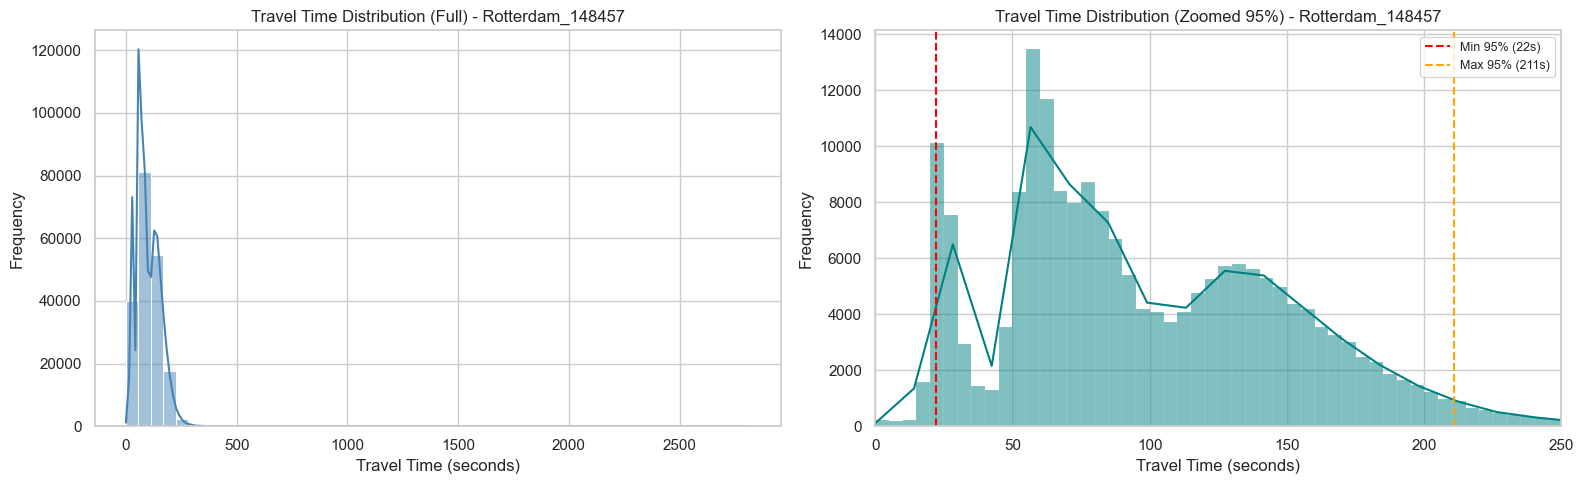

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Thiết lập phong cách biểu đồ
sns.set_theme(style="whitegrid")

# Tạo figure với 2 biểu đồ con cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- BIỂU ĐỒ BÊN TRÁI: Phân phối gốc (Full toàn bộ dữ liệu & outliers) ---
sns.histplot(df['travel_time'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title(f'Travel Time Distribution (Full) - {data_set_name}')
axes[0].set_xlabel('Travel Time (seconds)')
axes[0].set_ylabel('Frequency')

# --- BIỂU ĐỒ BÊN PHẢI: Phân phối phóng to (Zoomed vào vùng 95% dữ liệu: 22 - 211s) ---
# Dùng binwidth=5 để các cột chi tiết và không bị thưa thớt
sns.histplot(df['travel_time'], binwidth=5, kde=True, ax=axes[1], color='teal')
axes[1].set_title(f'Travel Time Distribution (Zoomed 95%) - {data_set_name}')
axes[1].set_xlabel('Travel Time (seconds)')
axes[1].set_ylabel('Frequency')

# Giới hạn trục X của biểu đồ phải từ 0 đến 250 (bao trọn khoảng [22, 211])
axes[1].set_xlim(0, 250) 

# Đánh dấu các mốc 95% để minh họa trực quan
axes[1].axvline(22, color='red', linestyle='--', linewidth=1.5, label='Min 95% (22s)')
axes[1].axvline(211, color='orange', linestyle='--', linewidth=1.5, label='Max 95% (211s)')
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

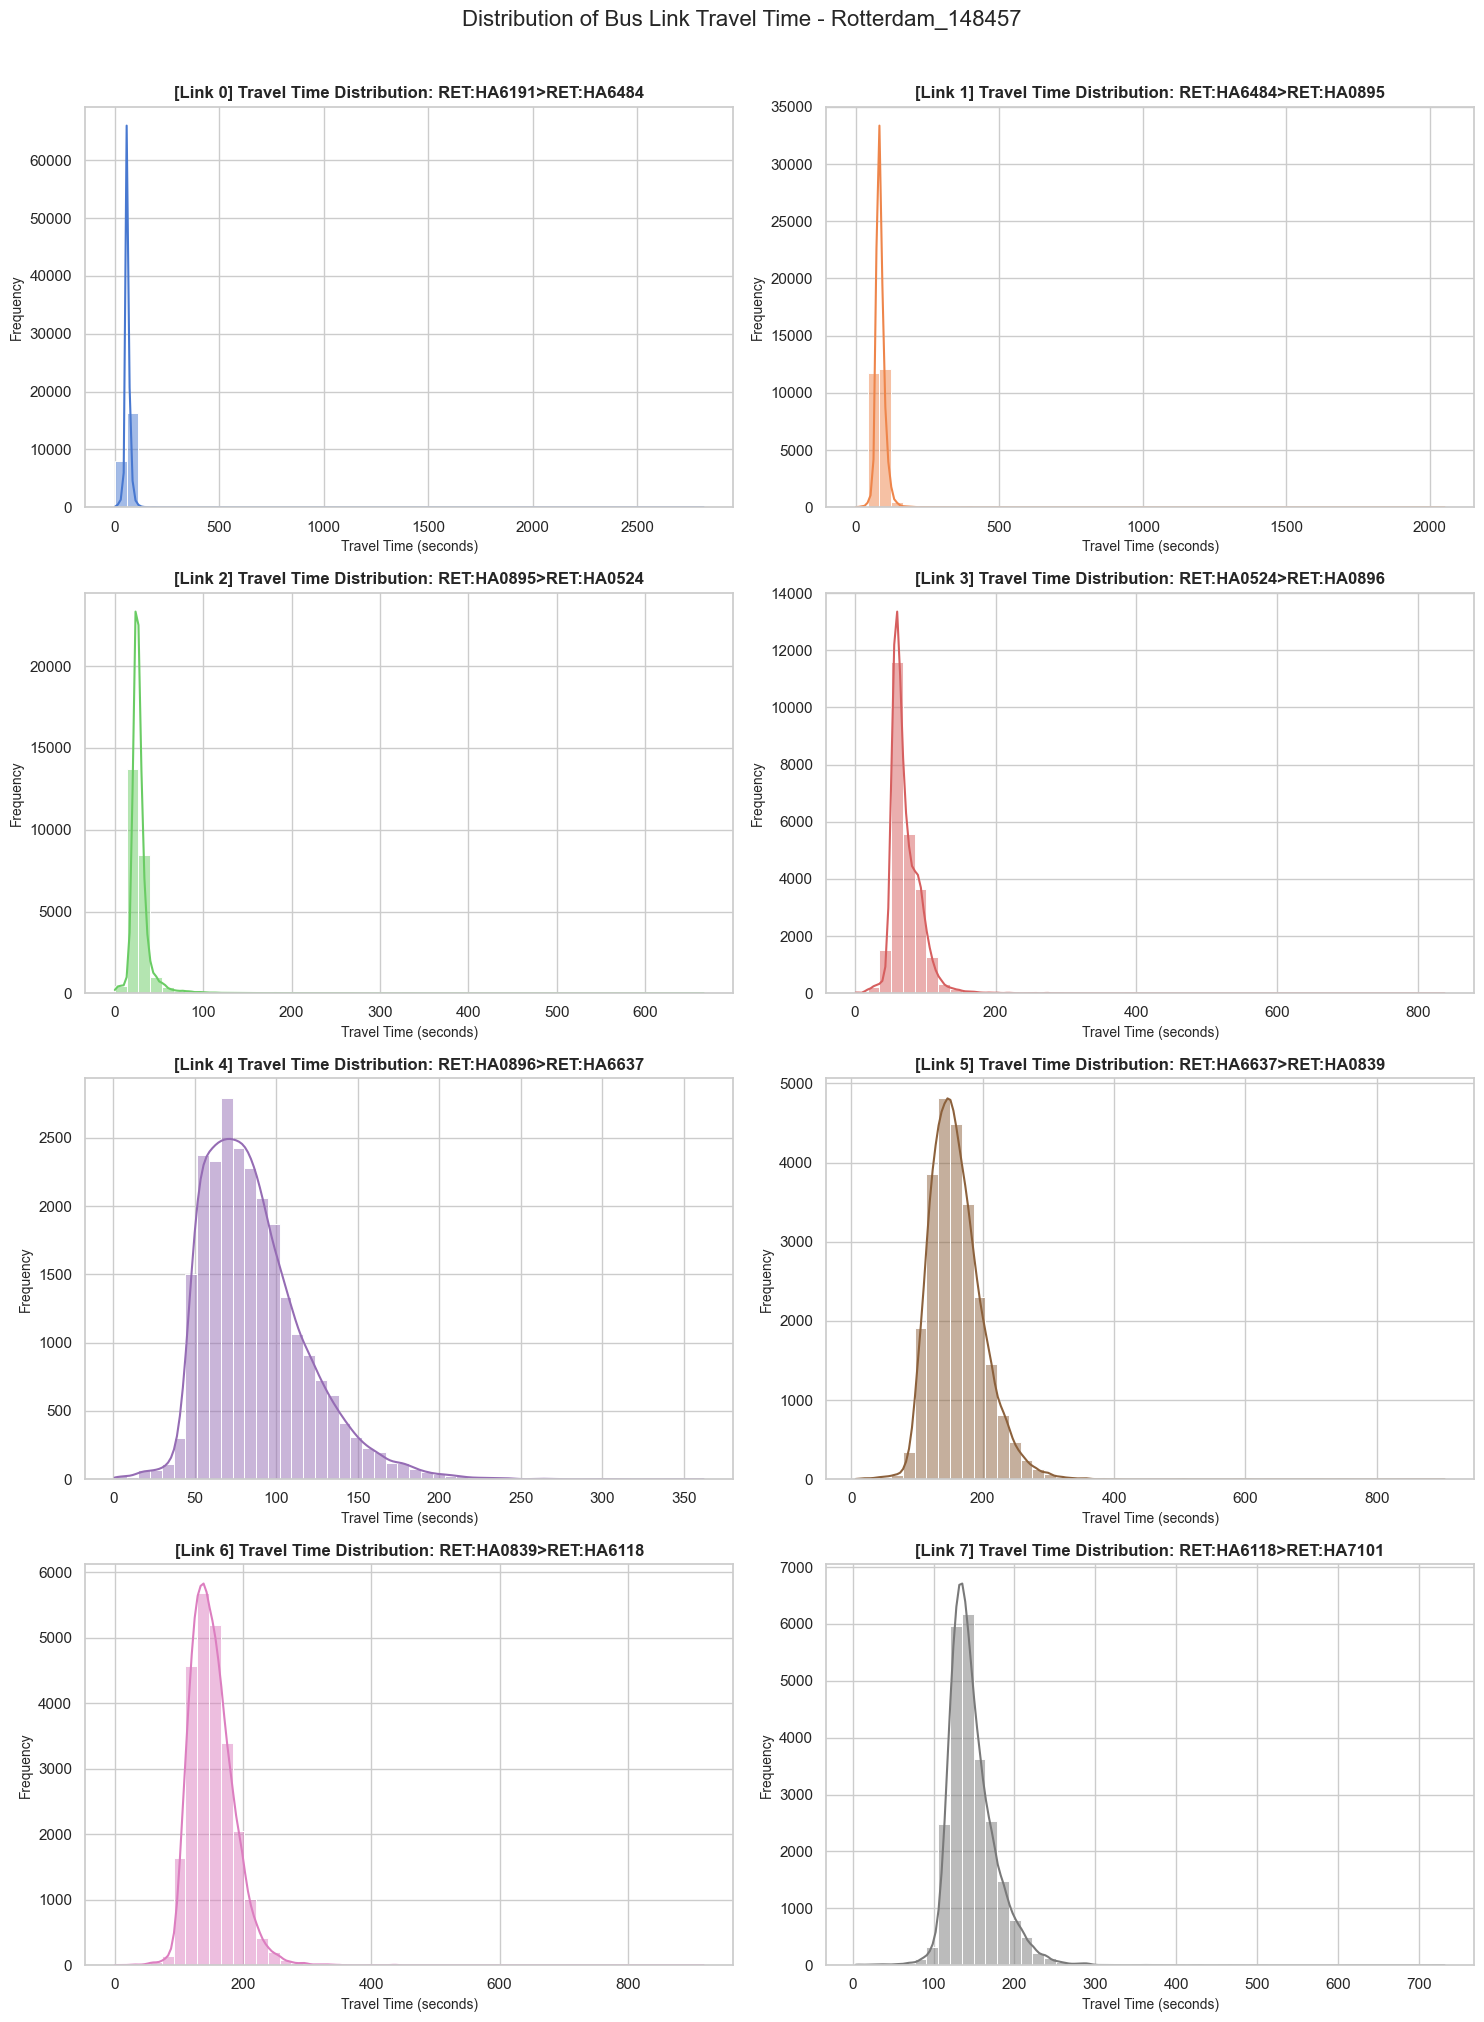

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

# Thiết lập phong cách biểu đồ
sns.set_theme(style="whitegrid")

# Lấy danh sách các link theo đúng thứ tự lộ trình thực tế [A]>[B] -> [B]>[C]
if isinstance(df['link'].dtype, pd.CategoricalDtype) and df['link'].cat.ordered:
    links = [lk for lk in df['link'].cat.categories if lk in df['link'].unique()]
else:
    link_meta = FixedIntervalDataset._build_link_metadata(df)
    links = link_meta.get("link_names", df['link'].unique().tolist())

num_links = len(links)

# Tính toán số hàng và số cột cho lưới subplot (tối đa 2 cột)
n_cols = 2
n_rows = (num_links + n_cols - 1) // n_cols

# Tạo figure với kích thước động dựa trên số lượng link
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()  # Đảm bảo không lỗi kể cả khi chỉ có 1 hàng/1 link

# Màu sắc cho các biểu đồ
colors = sns.color_palette("muted", num_links)

# Duyệt qua từng link theo thứ tự lộ trình để vẽ biểu đồ phân phối travel_time
for i, link in enumerate(links):
    ax = axes[i]
    # Lọc dữ liệu travel_time cho từng link cụ thể
    link_data = df[df['link'] == link]['travel_time']
    
    sns.histplot(link_data, bins=50, kde=True, ax=ax, color=colors[i])
    ax.set_title(f'[Link {i}] Travel Time Distribution: {link}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Travel Time (seconds)', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)

# Ẩn các ô subplot thừa (nếu số lượng link lẻ không lấp đầy lưới)
for j in range(num_links, len(axes)):
    fig.delaxes(axes[j])

# Tiêu đề chung cho toàn bộ figure
plt.suptitle(f'Distribution of Bus Link Travel Time - {data_set_name}', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## Phân tích Yếu tố Thời gian (Temporal Analysis)

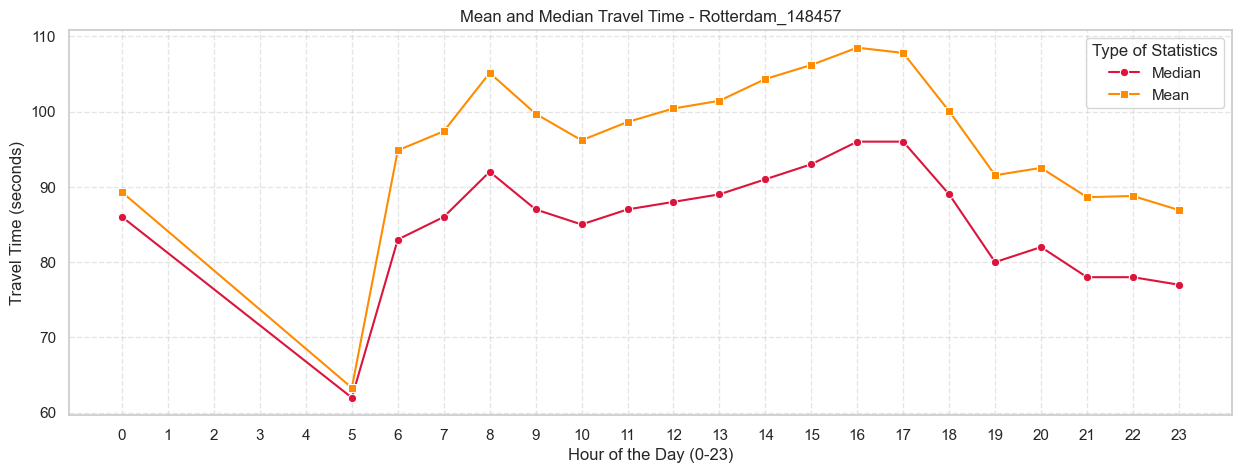

In [19]:
# Vì cell này chạy trước, cột 'hour' chưa tồn tại. 
# Ta sẽ trích xuất giờ trực tiếp từ cột 'from_time' để đưa vào trục x.

plt.figure(figsize=(15, 5))

# Lấy series giờ hiện tại
hours = df['from_time'].dt.hour

# Vẽ đường Trung vị (Median)
sns.lineplot(
    x=hours, 
    y=df['travel_time'], 
    estimator=np.median, 
    errorbar=None,
    color='crimson', 
    marker='o',
    label='Median'
)

# Vẽ đường Trung bình (Mean)
sns.lineplot(
    x=hours, 
    y=df['travel_time'], 
    estimator=np.mean, 
    errorbar=None,
    color='darkorange', 
    marker='s',
    label='Mean'
)

plt.title(f'Mean and Median Travel Time - {data_set_name}')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Travel Time (seconds)')
plt.xticks(range(0, 24))
plt.legend(title='Type of Statistics')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

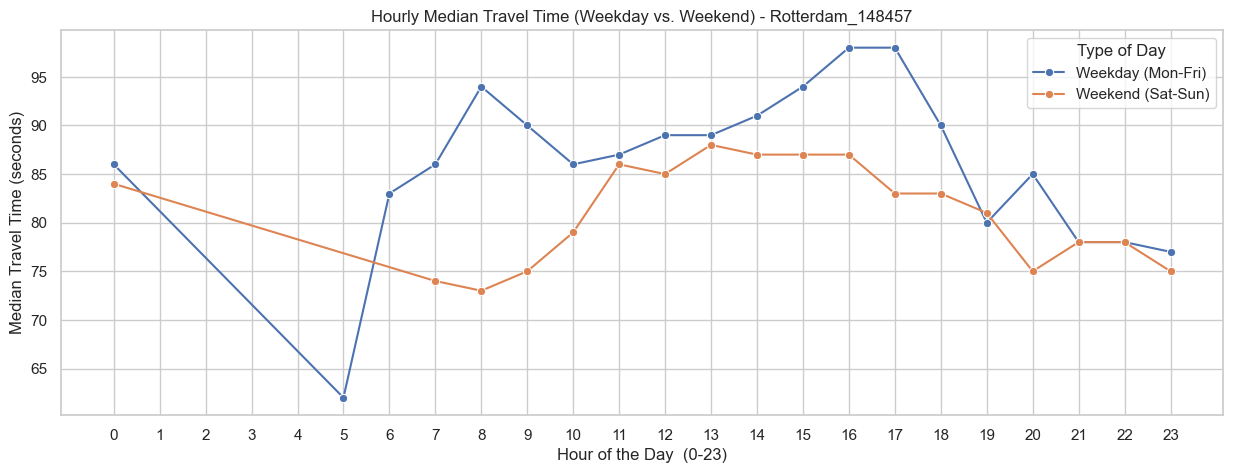

In [20]:
# Trích xuất các đặc trưng thời gian từ cột 'from_time'
df = df.copy()
df['hour'] = df['from_time'].dt.hour
df['dayofweek'] = df['from_time'].dt.dayofweek
df['is_weekend'] = df['dayofweek'] >= 5

# Tạo cột time_slot_15m (khung giờ 15 phút) như mô tả trong paper
df['time_slot_15m'] = df['from_time'].dt.floor('15min').dt.time

# Biểu đồ lineplot thể hiện Median Travel Time theo giờ trong ngày
plt.figure(figsize=(15, 5))
sns.lineplot(
    data=df, 
    x='hour', 
    y='travel_time', 
    hue='is_weekend', 
    estimator=np.median, 
    errorbar=None,
    marker='o'
)
plt.title(f'Hourly Median Travel Time (Weekday vs. Weekend) - {data_set_name}')
plt.xlabel('Hour of the Day  (0-23)')
plt.ylabel('Median Travel Time (seconds)')
plt.xticks(range(0, 24))
plt.legend(title='Type of Day', labels=['Weekday (Mon-Fri)', 'Weekend (Sat-Sun)'])
plt.show()

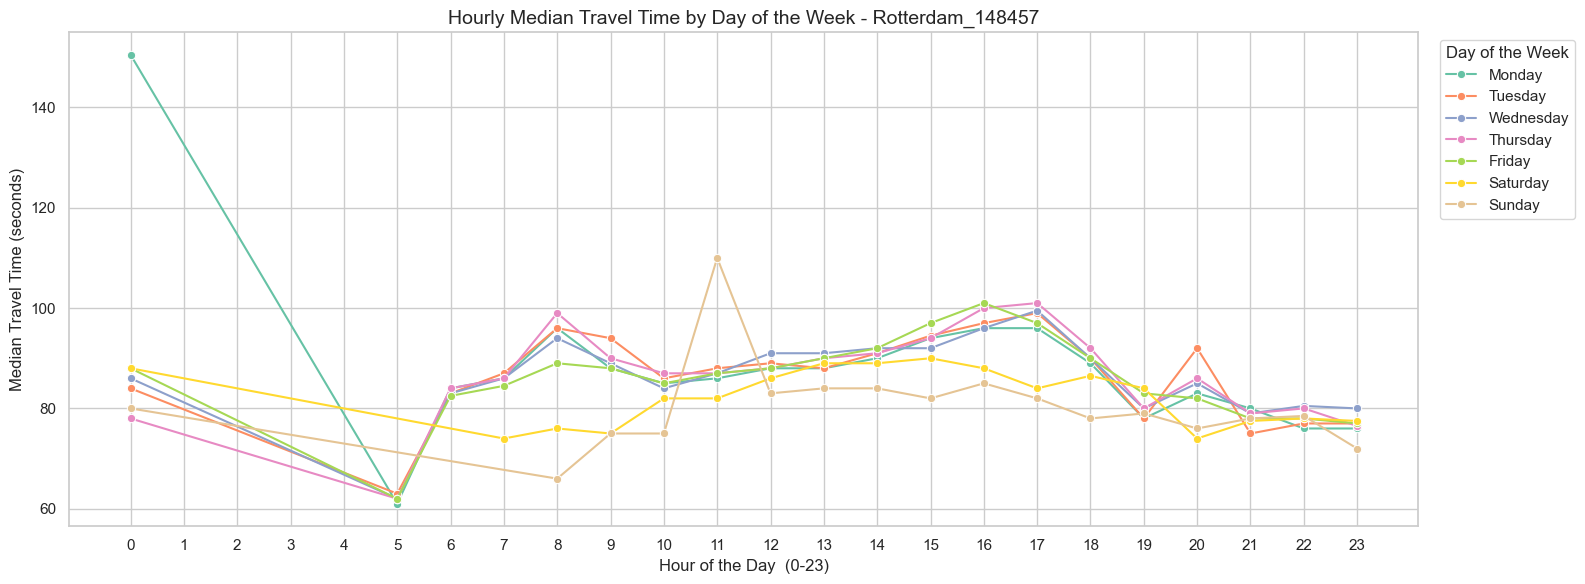

In [21]:
# Tạo từ điển ánh xạ số thứ tự ngày sang tên gọi tiếng Việt cho dễ nhìn trên chú giải (legend)
day_map = {
    0: 'Monday', 
    1: 'Tuesday', 
    2: 'Wednesday', 
    3: 'Thursday', 
    4: 'Friday', 
    5: 'Saturday', 
    6: 'Sunday'
}
df['day_name'] = df['dayofweek'].map(day_map)

# Định nghĩa thứ tự các ngày để biểu đồ và chú giải hiển thị đúng logic
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Vẽ biểu đồ
plt.figure(figsize=(16, 6))
sns.lineplot(
    data=df, 
    x='hour', 
    y='travel_time', 
    hue='day_name', 
    hue_order=day_order, # Ép thứ tự màu và legend theo ngày
    estimator=np.median, 
    errorbar=None,
    marker='o',
    palette='Set2' # Sử dụng dải màu Set2 để dễ phân biệt 7 đường khác nhau
)

plt.title(f'Hourly Median Travel Time by Day of the Week - {data_set_name}', fontsize=14)
plt.xlabel('Hour of the Day  (0-23)')
plt.ylabel('Median Travel Time (seconds)')
plt.xticks(range(0, 24))

# Đẩy khung chú giải (legend) ra ngoài biểu đồ để không che khuất đường vẽ
plt.legend(title='Day of the Week', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Thống kê số lượng mẫu dữ liệu theo thời gian trong ngày

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


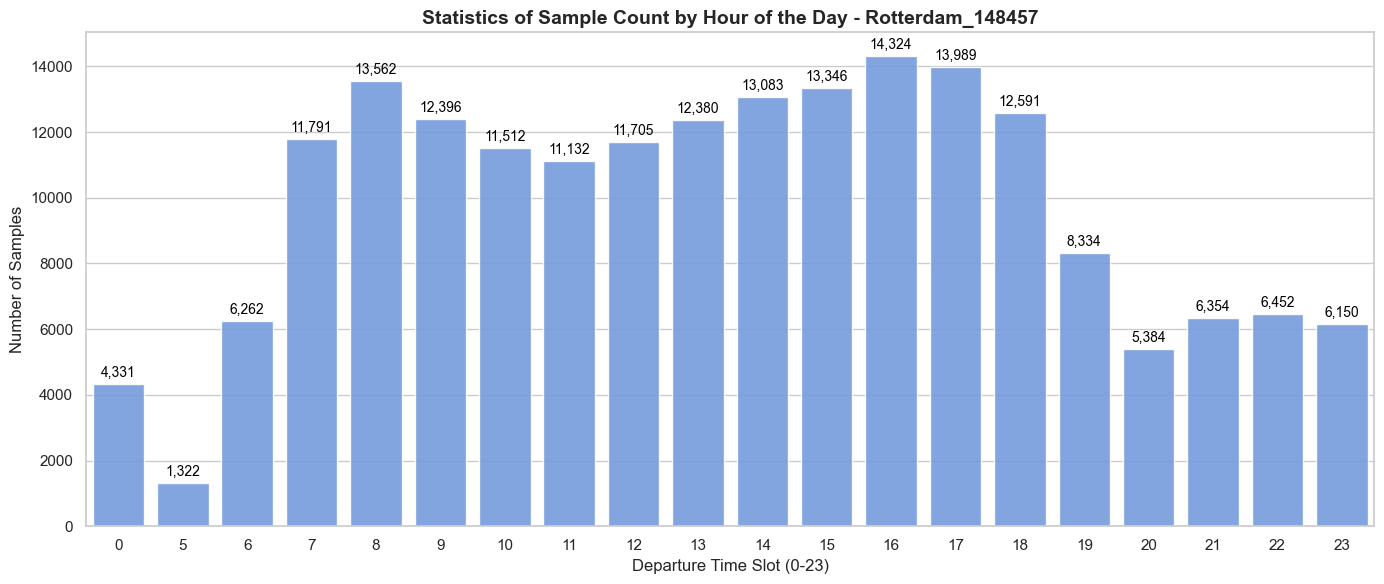

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập kích thước biểu đồ
plt.figure(figsize=(14, 6))

# Vẽ biểu đồ cột đếm số lượng mẫu theo giờ
# Lưu ý: Cột 'hour' đã được tạo ở cell code trước (df['hour'] = df['from_time'].dt.hour)
ax = sns.countplot(
    data=df, 
    x='hour', 
    color='cornflowerblue', # Dùng 1 màu đồng nhất để dễ nhìn tổng thể
    alpha=0.9
)

# Thêm tiêu đề và nhãn trục
plt.title(f'Statistics of Sample Count by Hour of the Day - {data_set_name}', fontsize=14, fontweight='bold')
plt.xlabel('Departure Time Slot (0-23)', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)

# Hiển thị giá trị cụ thể trên từng cột để dễ quan sát số liệu chi tiết
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                fontsize=10, color='black', xytext=(0, 3), 
                textcoords='offset points')

# Đảm bảo layout gọn gàng
plt.tight_layout()
plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


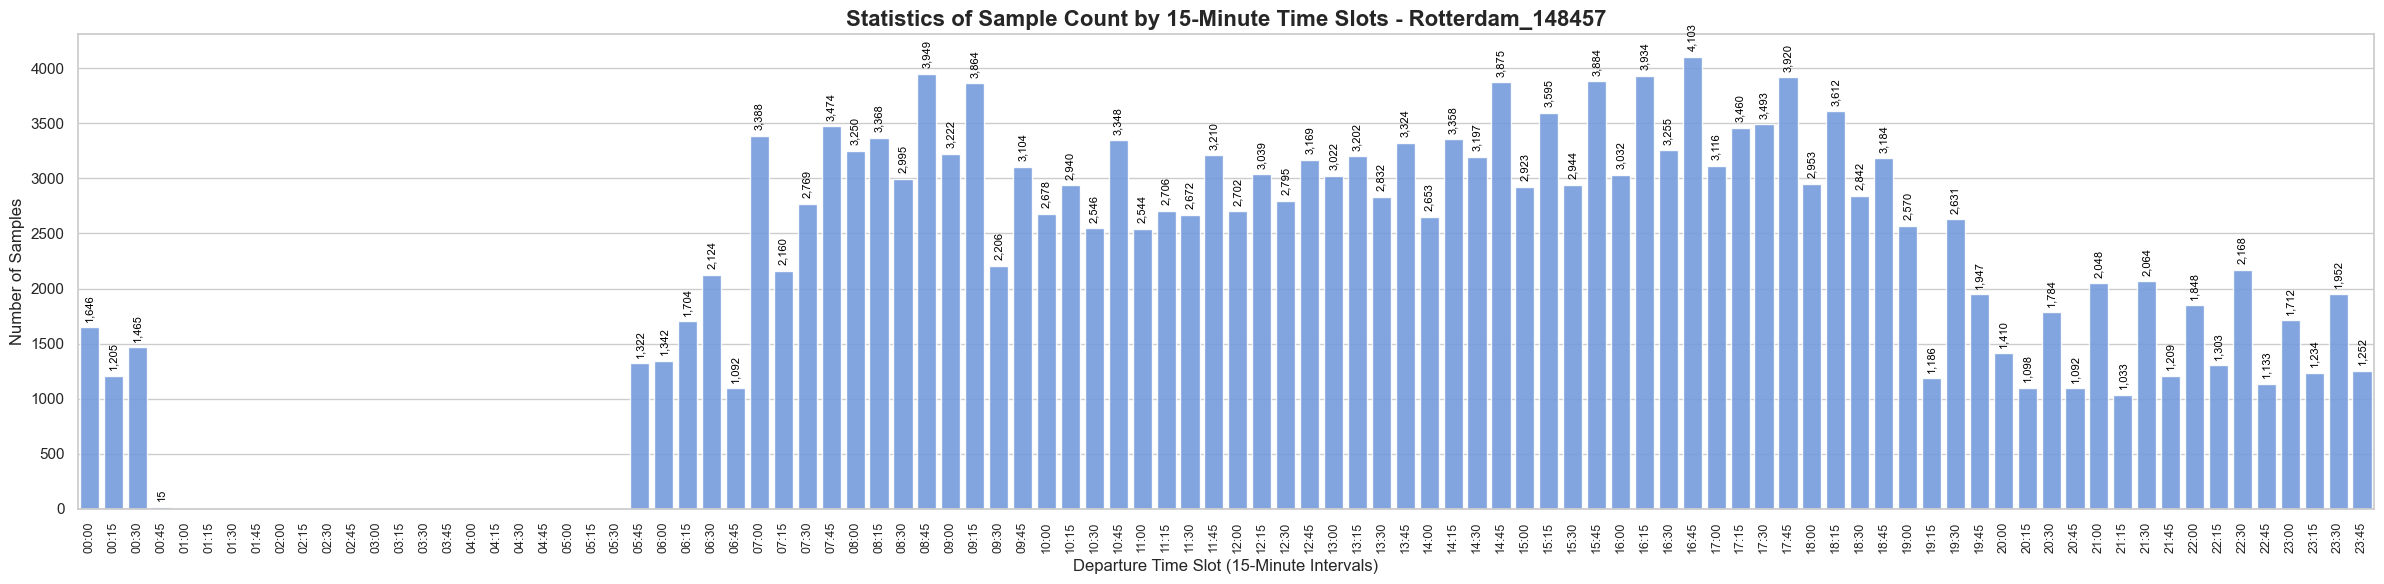

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Tạo cột 'time_slot_15m' từ cột datetime 'from_time'
# Dùng dt.floor('15min') để làm tròn thời gian xuống mốc 15 phút gần nhất, sau đó định dạng thành Giờ:Phút
df['time_slot_15m'] = df['from_time'].dt.floor('15min').dt.strftime('%H:%M')

# 2. Tạo danh sách đầy đủ 96 mốc 15 phút trong ngày để làm thứ tự chuẩn cho trục x
# (Đảm bảo trục X không bị nhảy cóc nếu có slot không có chuyến xe nào)
all_slots = pd.date_range("00:00", "23:59", freq="15min").strftime('%H:%M').tolist()

# Thiết lập kích thước biểu đồ (Kéo dài chiều ngang thành 20 hoặc 24 vì có đến 96 cột)
plt.figure(figsize=(24, 6))

# Vẽ biểu đồ cột đếm số lượng mẫu theo slot 15 phút
ax = sns.countplot(
    data=df, 
    x='time_slot_15m', 
    order=all_slots, # Bắt buộc sắp xếp theo thứ tự mốc thời gian
    color='cornflowerblue', 
    alpha=0.9
)

# Thêm tiêu đề và nhãn trục
plt.title(f'Statistics of Sample Count by 15-Minute Time Slots - {data_set_name}', fontsize=16, fontweight='bold')
plt.xlabel('Departure Time Slot (15-Minute Intervals)', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)

# Xoay nhãn trục x 90 độ để các chữ (00:00, 00:15...) không đè lên nhau
plt.xticks(rotation=90, fontsize=9)

# Hiển thị giá trị cụ thể trên từng cột
for p in ax.patches:
    height = p.get_height()
    # Chỉ hiển thị số lượng nếu có dữ liệu (> 0) để biểu đồ bớt rối
    if height > 0:
        ax.annotate(f'{int(height):,}', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    fontsize=8, color='black', 
                    xytext=(0, 4), textcoords='offset points',
                    rotation=90) # Xoay dọc số đếm để phù hợp với cột hẹp

# Đảm bảo layout gọn gàng không bị cắt mất nhãn
plt.tight_layout()
plt.show()

In [24]:
# Lấy danh sách các khung giờ thực tế đang có trong dữ liệu
existing_slots = df['time_slot_15m'].unique()

# Tìm các khung giờ trống bằng cách đối chiếu 96 mốc chuẩn với dữ liệu thực tế
empty_slots = [slot for slot in all_slots if slot not in existing_slots]

# In kết quả
print(f"Tổng số khung giờ 15 phút trong ngày: {len(all_slots)}")
print(f"Số khung giờ có dữ liệu: {len(existing_slots)}")

if len(empty_slots) > 0:
    print(f"\n⚠️ Phát hiện {len(empty_slots)} khung giờ KHÔNG có dữ liệu (0 chuyến xe):")
    
    # In danh sách các giờ trống, gom nhóm 10 khung giờ 1 dòng cho dễ nhìn
    for i in range(0, len(empty_slots), 10):
        print(" | ".join(empty_slots[i:i+10]))
else:
    print("\n✅ Không có khung giờ nào trống. Tất cả 96 slot (mỗi 15 phút) đều có ít nhất 1 chuyến xe.")

Tổng số khung giờ 15 phút trong ngày: 96
Số khung giờ có dữ liệu: 77

⚠️ Phát hiện 19 khung giờ KHÔNG có dữ liệu (0 chuyến xe):
01:00 | 01:15 | 01:30 | 01:45 | 02:00 | 02:15 | 02:30 | 02:45 | 03:00 | 03:15
03:30 | 03:45 | 04:00 | 04:15 | 04:30 | 04:45 | 05:00 | 05:15 | 05:30


# B. Sau khi pivot chia thành các timeslot 15min

In [25]:
# Tham số dataset
FFILL_LIMIT=8
IS_CALCULATE_RESIDUALS=True
IS_NORMALIZE=True

In [26]:
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

fixed_interval_dataset = FixedIntervalDataset(
    df,
    n_splits=5,
    freq="15min",
    ha_agg_func="median",
    ffill_limit=FFILL_LIMIT,
    mad_thresh=3*1.4826,
    interpolate_ha=True,
    add_time_feat=False,
    calculate_residuals=IS_CALCULATE_RESIDUALS,
    normalize=IS_NORMALIZE
)

INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 1: train=29840 (from 2022-04-04 05:52:50+02:00 to 2022-08-21 11:56:27.638888888+02:00), val=6064 (from 2022-08-21 11:56:27.638888888+02:00 to 2022-09-18 08:21:11.166666666+02:00), test=38696 (from 2022-09-18 08:21:11.166666666+02:00 to 2023-03-04 09:49:32.333333332+01:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 2: train=61586 (from 2022-04-04 05:52:50+02:00 to 2023-01-07 17:00:05.277777776+01:00), val=13014 (from 2023-01-07 17:00:05.277777776+01:00 to 2023-03-04 09:49:32.333333332+01:00), test=35546 (from 2023-03-04 09:49:32.333333332+01:00 to 2023-08-18 13:17:53.499999998+02:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 3: train=93480 (from 2022-04-04 05:52:50+02:00 to 2023-05-27 00:03:42.916666672+02:00), val=16666 (from 2023-05-27 00:03:42.916666672+02:00 to 2023-08-18 13:17:53.499999998+02:00), test=29486 (from 2023-08-18 13:17:53.499999998+02:00 to 2024-02-01 14:46:14.666666664+01:00)

In [27]:
# Tìm tất cả các link thuộc Route đó (df là khung dữ liệu pd.read_parquet của bạn)
links_in_route = df[df['route'] == route]['link'].unique()

# Tra cứu độ dài từ metadata của mô hình
link_names = fixed_interval_dataset.link_metadata['link_names']
link_lengths = fixed_interval_dataset.link_metadata['link_lengths']

print(f"--- ĐỘ DÀI CÁC LINK THUỘC ROUTE {route} ---")
count = 0
for name, length in zip(link_names, link_lengths):
    if name in links_in_route:
        count += 1
        print(f"{count}. {name:<40} : {length:7.2f} mét")

if count == 0:
    print("Vui lòng kiểm tra lại 'route', không tìm thấy link nào khớp.")

--- ĐỘ DÀI CÁC LINK THUỘC ROUTE 148457 ---
1. RET:HA6191>RET:HA6484                    :  630.51 mét
2. RET:HA6484>RET:HA0895                    :  607.80 mét
3. RET:HA0895>RET:HA0524                    :  186.24 mét
4. RET:HA0524>RET:HA0896                    :  468.32 mét
5. RET:HA0896>RET:HA6637                    :  494.07 mét
6. RET:HA6637>RET:HA0839                    : 1172.74 mét
7. RET:HA0839>RET:HA6118                    : 1151.66 mét
8. RET:HA6118>RET:HA7101                    : 1021.02 mét


In [ ]:
# Giả sử bạn đã khởi tạo đối tượng dataset từ class FixedIntervalDataset
# dataset = FixedIntervalDataset(df="đường_dẫn_file.parquet")

# Lấy các cột link từ ma trận đã pivot (ví dụ: tập train của split đầu tiên, bỏ qua các cột thời gian sin_tod/cos_tod nếu có)
pivoted_cols = fixed_interval_dataset.data_set[0][0].drop(columns=["sin_tod", "cos_tod"], errors="ignore").columns.tolist()

print("Danh sách các link sau khi pivot:")
for i, link_name in enumerate(pivoted_cols):
    print(f"link {i}: {link_name}")

Danh sách các link sau khi pivot:
link 0: RET:HA6191>RET:HA6484
link 1: RET:HA6484>RET:HA0895
link 2: RET:HA0895>RET:HA0524
link 3: RET:HA0524>RET:HA0896
link 4: RET:HA0896>RET:HA6637
link 5: RET:HA6637>RET:HA0839
link 6: RET:HA0839>RET:HA6118
link 7: RET:HA6118>RET:HA7101


In [29]:
# Số lượng record (1 record là travel time của 1 link) trong từng tập train, val, test cho mỗi split
# Là chưa qua pivot thành các timeslot 15min, mới chia split thôi
for train, val, test in fixed_interval_dataset.splits:
    print(f'Train: {len(train)}, Val: {len(val)}, Test: {len(test)}')

Train: 29840, Val: 6064, Test: 38696
Train: 61586, Val: 13014, Test: 35546
Train: 93480, Val: 16666, Test: 29486
Train: 119472, Val: 20160, Test: 27424
Train: 144782, Val: 22274, Test: 29343


In [30]:
# Hiển thị mẫu sample từ dataset
# Đã qua pivot thành các timeslot 15min, đã chia split, đã chuẩn hóa (nếu IS_NORMALIZE=True)

df_train, df_val, df_test, df_ha, scaler, absolut_matrix_train = fixed_interval_dataset.data_set[4] # old value: 4

display(absolut_matrix_train)

link,RET:HA6191>RET:HA6484,RET:HA6484>RET:HA0895,RET:HA0895>RET:HA0524,RET:HA0524>RET:HA0896,RET:HA0896>RET:HA6637,RET:HA6637>RET:HA0839,RET:HA0839>RET:HA6118,RET:HA6118>RET:HA7101
2022-04-04 05:45:00+02:00,58.0,91.0,30.0,63.0,65.0,NaN,NaN,NaN
2022-04-04 06:00:00+02:00,69.0,82.0,30.0,63.0,65.0,149.0,172.0,144.0
2022-04-04 06:15:00+02:00,69.0,82.0,28.0,81.0,54.0,154.0,171.0,162.0
2022-04-04 06:30:00+02:00,61.0,75.0,28.0,81.0,54.0,154.0,171.0,162.0
2022-04-04 06:45:00+02:00,59.5,84.0,20.5,78.0,46.0,153.0,130.0,166.0
...,...,...,...,...,...,...,...,...
2024-02-29 10:00:00+01:00,57.0,67.0,25.0,52.0,110.0,118.0,135.0,188.0
2024-02-29 10:15:00+01:00,57.0,67.0,25.0,52.0,110.0,118.0,135.0,128.0
2024-02-29 10:30:00+01:00,57.0,67.0,25.0,52.0,110.0,118.0,135.0,128.0
2024-02-29 10:45:00+01:00,57.0,67.0,24.0,87.0,145.0,200.0,173.0,128.0


In [31]:
# Hiển thị mẫu sample từ dataset
# Đã qua pivot thành các timeslot 15min, đã chia split, đã chuẩn hóa (nếu IS_NORMALIZE=True)

df_train, df_val, df_test, df_ha, scaler, absolut_matrix_train = fixed_interval_dataset.data_set[4] # old value: 4

display(df_train)

link,RET:HA6191>RET:HA6484,RET:HA6484>RET:HA0895,RET:HA0895>RET:HA0524,RET:HA0524>RET:HA0896,RET:HA0896>RET:HA6637,RET:HA6637>RET:HA0839,RET:HA0839>RET:HA6118,RET:HA6118>RET:HA7101
2022-04-04 05:45:00+02:00,-0.624745,0.994897,0.909975,0.189591,0.492749,NaN,NaN,NaN
2022-04-04 06:00:00+02:00,1.405677,0.000000,0.909975,0.189591,0.492749,0.627535,1.239220,0.711691
2022-04-04 06:15:00+02:00,1.405677,0.000000,0.909975,1.169146,-0.341134,0.336726,1.376911,1.156498
2022-04-04 06:30:00+02:00,-0.156186,0.000000,0.909975,1.169146,-0.341134,0.336726,1.376911,1.156498
2022-04-04 06:45:00+02:00,-0.156186,0.000000,0.341241,1.074350,-0.644364,-0.244892,-0.757301,1.134258
...,...,...,...,...,...,...,...,...
2024-02-29 10:00:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,2.268515
2024-02-29 10:15:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,-0.778412
2024-02-29 10:30:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,-0.778412
2024-02-29 10:45:00+01:00,-0.624745,-1.537568,-0.568734,1.011153,2.274224,1.454044,1.101528,-0.778412


In [32]:
import pandas as pd

meta = fixed_interval_dataset.link_metadata

# 1. In thông số tổng quan (chỉ in num_links)
print("=== THÔNG SỐ TỔNG QUAN ===")
print(f"- num_links: {meta.get('num_links')}")

# 2. Gom các danh sách/mảng có độ dài bằng nhau vào bảng (loại bỏ route_ids, from_stop_ids, to_stop_ids)
print("\n=== CHI TIẾT TỪNG LINK ===")
exclude_cols = {"route_ids", "from_stop_ids", "to_stop_ids"}

table_data = {
    k: v
    for k, v in meta.items()
    if hasattr(v, "__len__")
    and len(v) == meta.get("num_links")
    and k not in exclude_cols
}

df = pd.DataFrame(table_data)
print(df.to_string(index=False))

=== THÔNG SỐ TỔNG QUAN ===
- num_links: 8

=== CHI TIẾT TỪNG LINK ===
           link_names  link_ids  link_lengths  stop_sequence_norms
RET:HA6191>RET:HA6484         0    630.512337             0.000000
RET:HA6484>RET:HA0895         1    607.801755             0.142857
RET:HA0895>RET:HA0524         2    186.241599             0.285714
RET:HA0524>RET:HA0896         3    468.315653             0.428571
RET:HA0896>RET:HA6637         4    494.066148             0.571429
RET:HA6637>RET:HA0839         5   1172.739468             0.714286
RET:HA0839>RET:HA6118         6   1151.663230             0.857143
RET:HA6118>RET:HA7101         7   1021.018272             1.000000
